Load NB0 artifacts + imports

In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    print(root, files)

/kaggle/input []
/kaggle/input/notebooks []
/kaggle/input/notebooks/sumiayasharif []
/kaggle/input/notebooks/sumiayasharif/nb0-eda-data-prep ['pixel_class_distribution.csv', 'split_manifest.json', 'sanity_check_grid.png', '__results__.html', '__notebook__.ipynb', '__output__.json', 'pixel_class_distribution.png', 'custom.css']
/kaggle/input/notebooks/sumiayasharif/nb0-eda-data-prep/__results___files ['__results___10_5.png', '__results___10_0.png', '__results___10_4.png', '__results___10_3.png', '__results___10_1.png', '__results___23_0.png', '__results___10_6.png', '__results___10_2.png', '__results___6_0.png']
/kaggle/input/notebooks/sumiayasharif/nb0-eda-data-prep/nb0_artifacts ['pixel_class_distribution.csv', 'split_manifest.json', 'common_config.json', 'seg_common.py']
/kaggle/input/datasets []
/kaggle/input/datasets/sumiayasharif []
/kaggle/input/datasets/sumiayasharif/foodbd []
/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B []
/kagg

In [2]:
import sys, os

# Real path found via os.walk — NB0 was attached as a "Notebook" input, not a "Dataset" input
ARTIFACT_DIR = "/kaggle/input/notebooks/sumiayasharif/nb0-eda-data-prep/nb0_artifacts"
sys.path.append(ARTIFACT_DIR)

import time, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

from seg_common import (
    load_common_config, load_split_manifest,
    polygons_to_mask, get_transforms, FoodSegDataset
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

cfg = load_common_config(f"{ARTIFACT_DIR}/common_config.json")
split = load_split_manifest(f"{ARTIFACT_DIR}/split_manifest.json")

IMG_SIZE = cfg["img_size"]
NUM_CLASSES = cfg["num_classes_total"]
CLASS_NAMES = ["background"] + cfg["class_names"]
print(f"Num classes (incl. background): {NUM_CLASSES}")

Device: cuda
Num classes (incl. background): 68


In [3]:
# Check whether the first few paths in the split manifest actually exist in THIS notebook's environment
sample_paths = split["train"][:3]
for p in sample_paths:
    print(p, "-> exists:", os.path.exists(p))

/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-0002.jpg -> exists: True
/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-0003.jpg -> exists: True
/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-0004.jpg -> exists: True


Datasets & Dataloaders (identical split from NB0)

In [4]:
train_transform = get_transforms(IMG_SIZE, train=True)
val_transform    = get_transforms(IMG_SIZE, train=False)

train_ds = FoodSegDataset(split["train"], train_transform, bg_is_zero=cfg["bg_is_zero"])
valid_ds = FoodSegDataset(split["valid"], val_transform,  bg_is_zero=cfg["bg_is_zero"])
test_ds  = FoodSegDataset(split["test"],  val_transform,  bg_is_zero=cfg["bg_is_zero"])

BATCH_SIZE = 8   # adjust down to 4 if you hit OOM on T4/P100 with IMG_SIZE=512

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train batches: {len(train_loader)}, Valid: {len(valid_loader)}, Test: {len(test_loader)}")

Train batches: 309, Valid: 88, Test: 45


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/kaggle/input/notebooks/sumiayasharif/nb0-eda-data-prep/nb0_artifacts/seg_common.py:40: UserWarning: Argument(s) 'value, mask_value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=15, p=0.5,
/kaggle/input/notebooks/sumiayasharif/nb0-eda-data-prep/nb0_artifacts/seg_common.py:45: UserWarning: Argument(s) 'max_holes, max_height, max_width, fill_value, mask_fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=4, max_height=32, max_width=32, fill_value=0, mask_fill_value=0, p=0.2),


Task E: Config cell (required — all hyperparameters visible in one place)

In [5]:
CONFIG = {
    "model": "DeepLabV3-ResNet50",
    "backbone": "ResNet-50 (COCO-pretrained)",
    "num_classes": NUM_CLASSES,
    "input_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": 50,                     # minimum floor per instructions; extend if still improving
    "optimizer": "AdamW",
    "lr": 1e-4,
    "lr_schedule": "CosineAnnealingLR",
    "weight_decay": 1e-4,
    "loss_function": "Weighted CrossEntropy + Dice (combo)",
    "class_weighting": "inverse sqrt of pixel frequency (from NB0 pixel_class_distribution.csv)",
    "seed": SEED,
}
print(json.dumps(CONFIG, indent=2))

{
  "model": "DeepLabV3-ResNet50",
  "backbone": "ResNet-50 (COCO-pretrained)",
  "num_classes": 68,
  "input_size": 512,
  "batch_size": 8,
  "epochs": 50,
  "optimizer": "AdamW",
  "lr": 0.0001,
  "lr_schedule": "CosineAnnealingLR",
  "weight_decay": 0.0001,
  "loss_function": "Weighted CrossEntropy + Dice (combo)",
  "class_weighting": "inverse sqrt of pixel frequency (from NB0 pixel_class_distribution.csv)",
  "seed": 42
}


Class weights (from NB0's pixel distribution, addressing Task A's imbalance finding)

In [6]:
dist_df = pd.read_csv(f"{ARTIFACT_DIR}/pixel_class_distribution.csv")
dist_df = dist_df.sort_values("class_id").reset_index(drop=True)

pixel_counts = dist_df["pixel_count"].values.astype(np.float64)
pixel_counts = np.clip(pixel_counts, 1, None)

inv_sqrt_freq = 1.0 / np.sqrt(pixel_counts)
class_weights = inv_sqrt_freq / inv_sqrt_freq.sum() * NUM_CLASSES
class_weights = np.clip(class_weights, 0.1, 10.0)
class_weights[0] *= 0.5

class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)
print("Class weight range:", class_weights.min(), "-", class_weights.max())

Class weight range: 0.05 - 2.340437993376195


In [7]:
print("ARTIFACT_DIR =", ARTIFACT_DIR)
for f in os.listdir(ARTIFACT_DIR):
    print(" -", f)

ARTIFACT_DIR = /kaggle/input/notebooks/sumiayasharif/nb0-eda-data-prep/nb0_artifacts
 - pixel_class_distribution.csv
 - split_manifest.json
 - common_config.json
 - seg_common.py


Model setup (pretrained backbone, head replaced for our class count)

In [8]:
weights = DeepLabV3_ResNet50_Weights.DEFAULT
model = deeplabv3_resnet50(weights=weights)

# Replace classifier head to match NUM_CLASSES
model.classifier[4] = nn.Conv2d(256, NUM_CLASSES, kernel_size=1)
if model.aux_classifier is not None:
    model.aux_classifier[4] = nn.Conv2d(256, NUM_CLASSES, kernel_size=1)

model = model.to(device)
print(f"Total params: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 196MB/s]


Total params: 42.0M


Loss function (weighted CE + Dice combo)

In [9]:
def dice_loss(logits, targets, num_classes, eps=1e-6):
    probs = F.softmax(logits, dim=1)
    targets_onehot = F.one_hot(targets, num_classes).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)
    intersection = torch.sum(probs * targets_onehot, dims)
    union = torch.sum(probs + targets_onehot, dims)
    dice = (2 * intersection + eps) / (union + eps)
    return 1 - dice.mean()

ce_loss_fn = nn.CrossEntropyLoss(weight=class_weights_t)

def combo_loss(outputs, targets):
    logits = outputs["out"]
    ce = ce_loss_fn(logits, targets)
    dl = dice_loss(logits, targets, NUM_CLASSES)
    loss = 0.6 * ce + 0.4 * dl
    if "aux" in outputs and model.training:
        aux_ce = ce_loss_fn(outputs["aux"], targets)
        loss = loss + 0.4 * aux_ce
    return loss

mIoU metric helper (used for validation monitoring)

In [10]:
def compute_miou(conf_mat, num_classes):
    ious = []
    for c in range(num_classes):
        tp = conf_mat[c, c]
        fp = conf_mat[:, c].sum() - tp
        fn = conf_mat[c, :].sum() - tp
        denom = tp + fp + fn
        ious.append(tp / denom if denom > 0 else np.nan)
    return np.nanmean(ious), ious

def update_confusion(conf_mat, preds, targets, num_classes):
    p = preds.flatten().cpu().numpy()
    t = targets.flatten().cpu().numpy()
    mask = (t >= 0) & (t < num_classes)
    conf_mat += np.bincount(
        num_classes * t[mask].astype(int) + p[mask].astype(int),
        minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    return conf_mat

Training loop (≥50 epochs, extend if still improving)

In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"])
scaler = torch.cuda.amp.GradScaler()

MIN_EPOCHS = 50
best_val_miou = -1.0
best_epoch = 0
patience_extend = 5     # how many epochs of continued improvement we allow past floor before stopping
history = {"train_loss": [], "val_loss": [], "val_miou": []}

start_time = time.time()
epoch = 0
no_improve_streak = 0

while True:
    epoch += 1
    model.train()
    running_loss = 0.0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(imgs)
            loss = combo_loss(outputs, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()
    train_loss = running_loss / len(train_loader)
    scheduler.step()

    # Validation
    model.eval()
    val_loss = 0.0
    conf_mat = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    with torch.no_grad():
        for imgs, masks in valid_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            outputs = model(imgs)
            loss = ce_loss_fn(outputs["out"], masks)
            val_loss += loss.item()
            preds = outputs["out"].argmax(1)
            conf_mat = update_confusion(conf_mat, preds, masks, NUM_CLASSES)
    val_loss /= len(valid_loader)
    val_miou, _ = compute_miou(conf_mat, NUM_CLASSES)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_miou"].append(val_miou)

    print(f"Epoch {epoch:03d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_mIoU={val_miou:.4f}")

    improved = val_miou > best_val_miou
    if improved:
        best_val_miou = val_miou
        best_epoch = epoch
        no_improve_streak = 0
        torch.save(model.state_dict(), "deeplabv3_best.pth")
    else:
        no_improve_streak += 1

    # Stop only once we've hit the 50-epoch floor AND validation has stopped improving
    if epoch >= MIN_EPOCHS and no_improve_streak >= patience_extend:
        print(f"Stopping at epoch {epoch}: no improvement for {patience_extend} epochs past the 50-epoch floor.")
        break
    if epoch >= MIN_EPOCHS + 30:  # hard safety cap so training doesn't run indefinitely
        print("Hit safety cap of 80 epochs, stopping.")
        break

total_train_time = time.time() - start_time
CONFIG["actual_epochs_trained"] = epoch
CONFIG["best_epoch"] = best_epoch
CONFIG["total_training_time_sec"] = round(total_train_time, 1)
print(f"\nTraining complete. Best val mIoU={best_val_miou:.4f} at epoch {best_epoch}. "
      f"Total time: {total_train_time/60:.1f} min")

/tmp/ipykernel_24/3328575931.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_24/3328575931.py:22: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 001 | train_loss=3.1438 | val_loss=1.7736 | val_mIoU=0.1650
Epoch 002 | train_loss=2.1319 | val_loss=1.3250 | val_mIoU=0.2213
Epoch 003 | train_loss=1.7647 | val_loss=1.1069 | val_mIoU=0.2997
Epoch 004 | train_loss=1.5595 | val_loss=1.0039 | val_mIoU=0.3344
Epoch 005 | train_loss=1.4100 | val_loss=1.0040 | val_mIoU=0.3214
Epoch 006 | train_loss=1.3187 | val_loss=0.8576 | val_mIoU=0.3890
Epoch 007 | train_loss=1.2097 | val_loss=0.8126 | val_mIoU=0.3948
Epoch 008 | train_loss=1.1490 | val_loss=0.7804 | val_mIoU=0.4223
Epoch 009 | train_loss=1.0976 | val_loss=0.7514 | val_mIoU=0.4261
Epoch 010 | train_loss=1.0479 | val_loss=0.7128 | val_mIoU=0.4369
Epoch 011 | train_loss=0.9911 | val_loss=0.7124 | val_mIoU=0.4552
Epoch 012 | train_loss=0.9661 | val_loss=0.7294 | val_mIoU=0.4466
Epoch 013 | train_loss=0.9207 | val_loss=0.7415 | val_mIoU=0.4543
Epoch 014 | train_loss=0.8950 | val_loss=0.7083 | val_mIoU=0.4512
Epoch 015 | train_loss=0.8543 | val_loss=0.6991 | val_mIoU=0.4656
Epoch 016 

Training curves

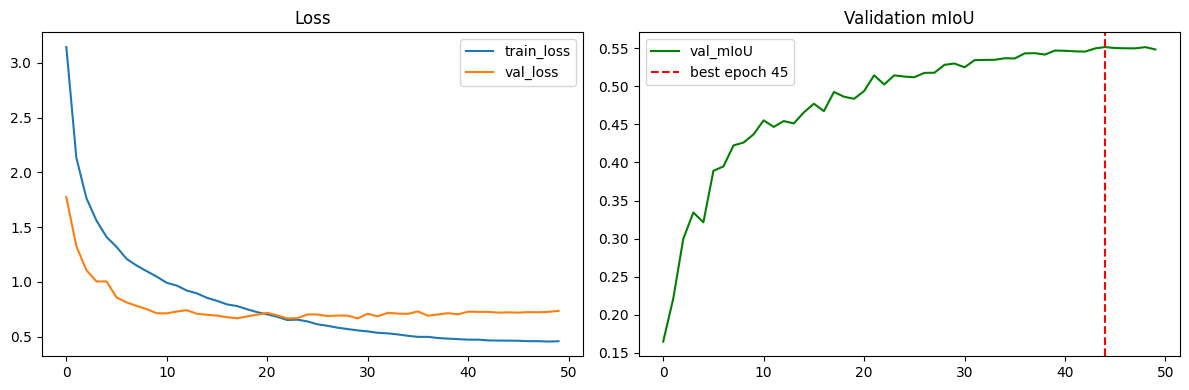

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="train_loss")
axes[0].plot(history["val_loss"], label="val_loss")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history["val_miou"], label="val_mIoU", color="green")
axes[1].axvline(best_epoch-1, color="red", linestyle="--", label=f"best epoch {best_epoch}")
axes[1].set_title("Validation mIoU"); axes[1].legend()
plt.tight_layout()
plt.savefig("deeplabv3_training_curves.png", dpi=150)
plt.show()

Task F: Load best checkpoint, evaluate on held-out TEST split

In [13]:
model.load_state_dict(torch.load("deeplabv3_best.pth"))
model.eval()

conf_mat_test = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
per_image_ious = []  # (index, iou) for Task G worst-case analysis

with torch.no_grad():
    for batch_idx, (imgs, masks) in enumerate(test_loader):
        imgs, masks = imgs.to(device), masks.to(device)
        outputs = model(imgs)
        preds = outputs["out"].argmax(1)
        conf_mat_test = update_confusion(conf_mat_test, preds, masks, NUM_CLASSES)

        for i in range(imgs.size(0)):
            p, t = preds[i], masks[i]
            classes_present = torch.unique(t)
            ious = []
            for c in classes_present:
                c = c.item()
                if c == 0:  # skip background for per-image "worst" ranking
                    continue
                tp = ((p == c) & (t == c)).sum().item()
                fp_fn = ((p == c) | (t == c)).sum().item()
                if fp_fn > 0:
                    ious.append(tp / fp_fn)
            img_iou = np.mean(ious) if ious else np.nan
            global_idx = batch_idx * BATCH_SIZE + i
            per_image_ious.append((global_idx, img_iou))

# Metrics
miou_test, per_class_iou = compute_miou(conf_mat_test, NUM_CLASSES)
pixel_acc = np.trace(conf_mat_test) / conf_mat_test.sum()
per_class_acc = [conf_mat_test[c,c] / conf_mat_test[c,:].sum() if conf_mat_test[c,:].sum()>0 else np.nan
                  for c in range(NUM_CLASSES)]
mean_pixel_acc = np.nanmean(per_class_acc)

def dice_from_conf(conf_mat, num_classes):
    dices = []
    for c in range(num_classes):
        tp = conf_mat[c,c]
        fp = conf_mat[:,c].sum() - tp
        fn = conf_mat[c,:].sum() - tp
        denom = 2*tp + fp + fn
        dices.append(2*tp/denom if denom>0 else np.nan)
    return dices

per_class_dice = dice_from_conf(conf_mat_test, NUM_CLASSES)

results_df = pd.DataFrame({
    "class_id": range(NUM_CLASSES),
    "class_name": CLASS_NAMES,
    "IoU": per_class_iou,
    "PixelAcc": per_class_acc,
    "Dice": per_class_dice,
})
results_df.to_csv("deeplabv3_test_metrics_per_class.csv", index=False)

summary = {
    "model": "DeepLabV3-ResNet50",
    "mIoU": miou_test,
    "overall_pixel_accuracy": pixel_acc,
    "mean_pixel_accuracy": mean_pixel_acc,
    "mean_dice": np.nanmean(per_class_dice),
    "epochs_trained": CONFIG["actual_epochs_trained"],
    "training_time_sec": CONFIG["total_training_time_sec"],
}
with open("deeplabv3_test_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
results_df.sort_values("IoU").head(15)

{
  "model": "DeepLabV3-ResNet50",
  "mIoU": 0.5207517788623902,
  "overall_pixel_accuracy": 0.9410296432019631,
  "mean_pixel_accuracy": 0.7051967772045167,
  "mean_dice": 0.6359458884332407,
  "epochs_trained": 50,
  "training_time_sec": 20525.2
}


,class_id,class_name,IoU,PixelAcc,Dice
24,24,egg,0.000000,NaN,0.000000
18,18,chomchom,0.000000,0.000000,0.000000
57,57,roll,0.000000,0.000000,0.000000
33,33,kabab,0.044162,0.086583,0.084588
63,63,tomato,0.055416,0.067316,0.105013
62,62,sweets,0.058397,0.069138,0.110349
66,66,vorta,0.058699,0.284149,0.110888
30,30,guava,0.061912,0.062594,0.116606
2,2,apple,0.103012,0.361136,0.186783
50,50,piyaju,0.117089,0.201171,0.209632


Confusion matrix visualization

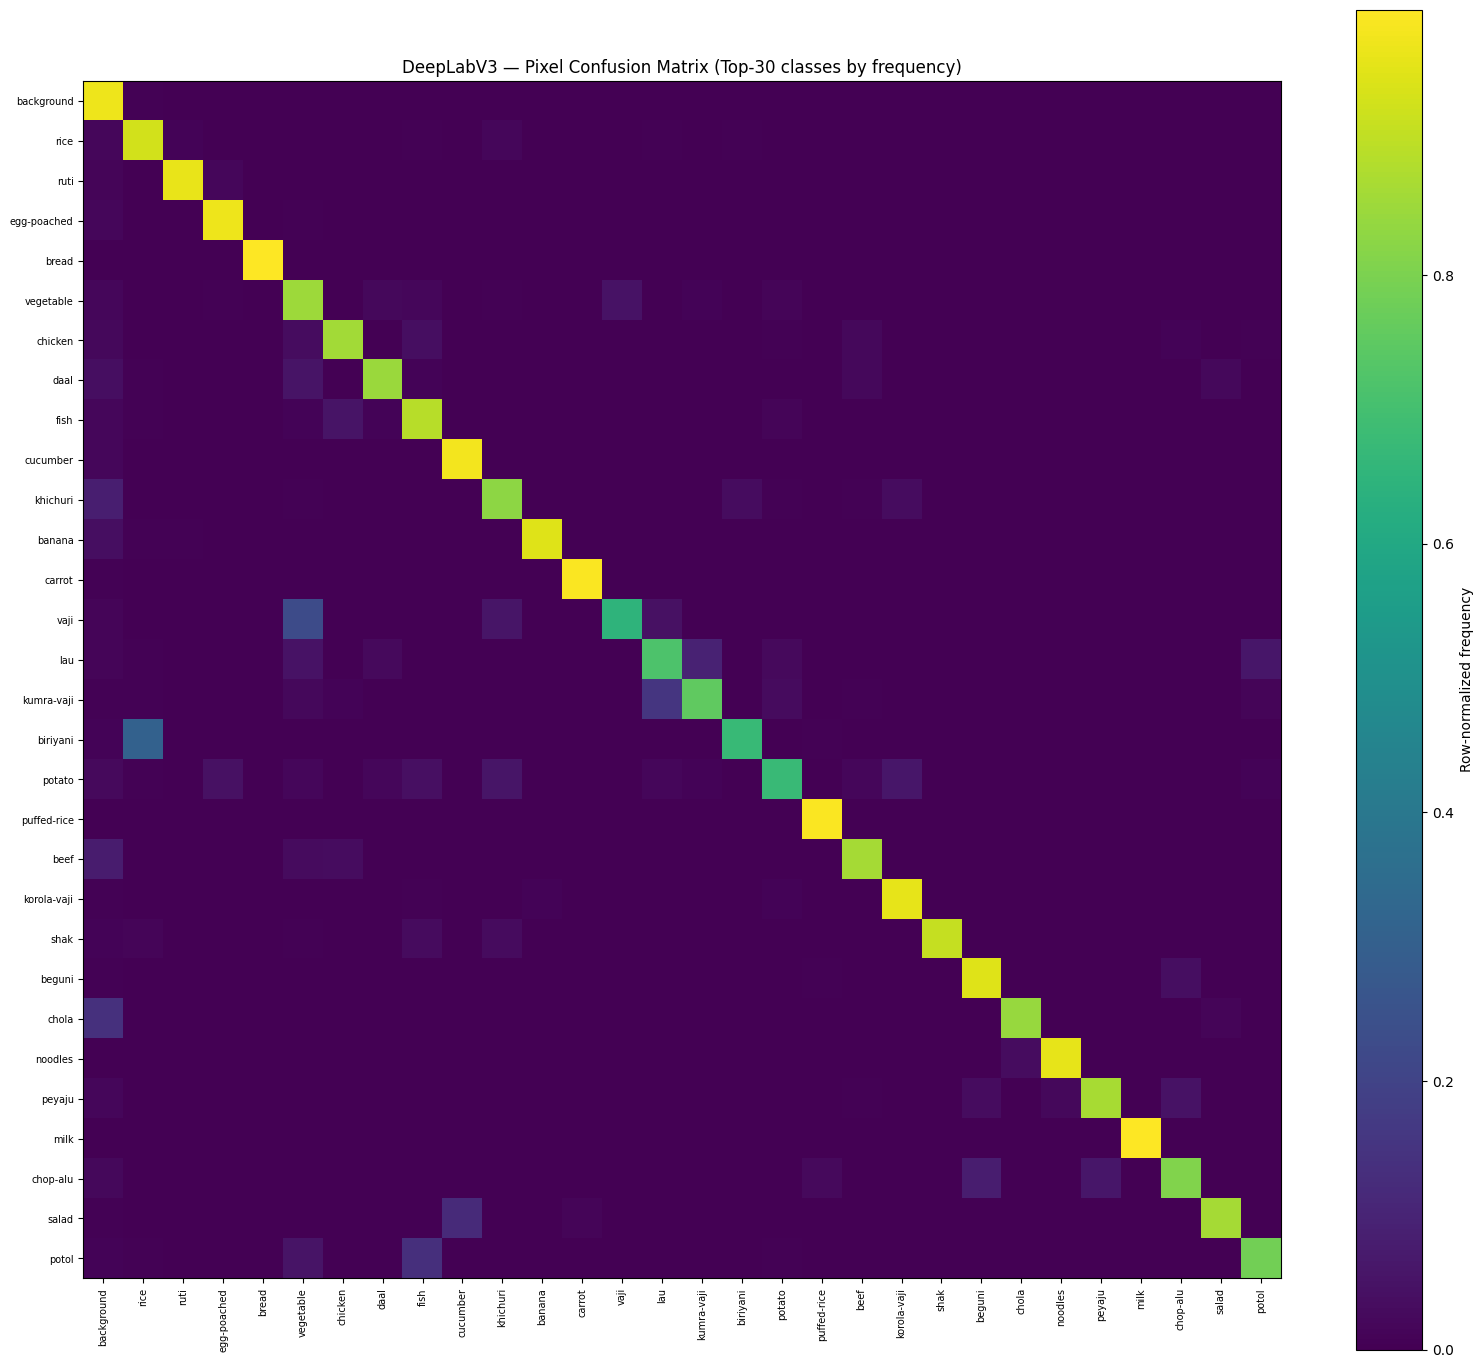

In [14]:
plt.figure(figsize=(16,14))
# Normalize per-row for readability, only show top-30 most frequent classes to keep it legible
top_classes = dist_df.sort_values("pixel_count", ascending=False)["class_id"].values[:30]
sub_conf = conf_mat_test[np.ix_(top_classes, top_classes)]
sub_conf_norm = sub_conf / (sub_conf.sum(axis=1, keepdims=True) + 1e-9)

plt.imshow(sub_conf_norm, cmap="viridis")
plt.colorbar(label="Row-normalized frequency")
plt.xticks(range(len(top_classes)), [CLASS_NAMES[c] for c in top_classes], rotation=90, fontsize=7)
plt.yticks(range(len(top_classes)), [CLASS_NAMES[c] for c in top_classes], fontsize=7)
plt.title("DeepLabV3 — Pixel Confusion Matrix (Top-30 classes by frequency)")
plt.tight_layout()
plt.savefig("deeplabv3_confusion_matrix.png", dpi=150)
plt.show()

Task G: Error Analysis — worst-performing test images

Worst 5 test images (by mean per-image IoU, excluding background):
  idx=152, IoU=0.0000
  idx=181, IoU=0.0000
  idx=190, IoU=0.0271
  idx=198, IoU=0.0363
  idx=308, IoU=0.0570


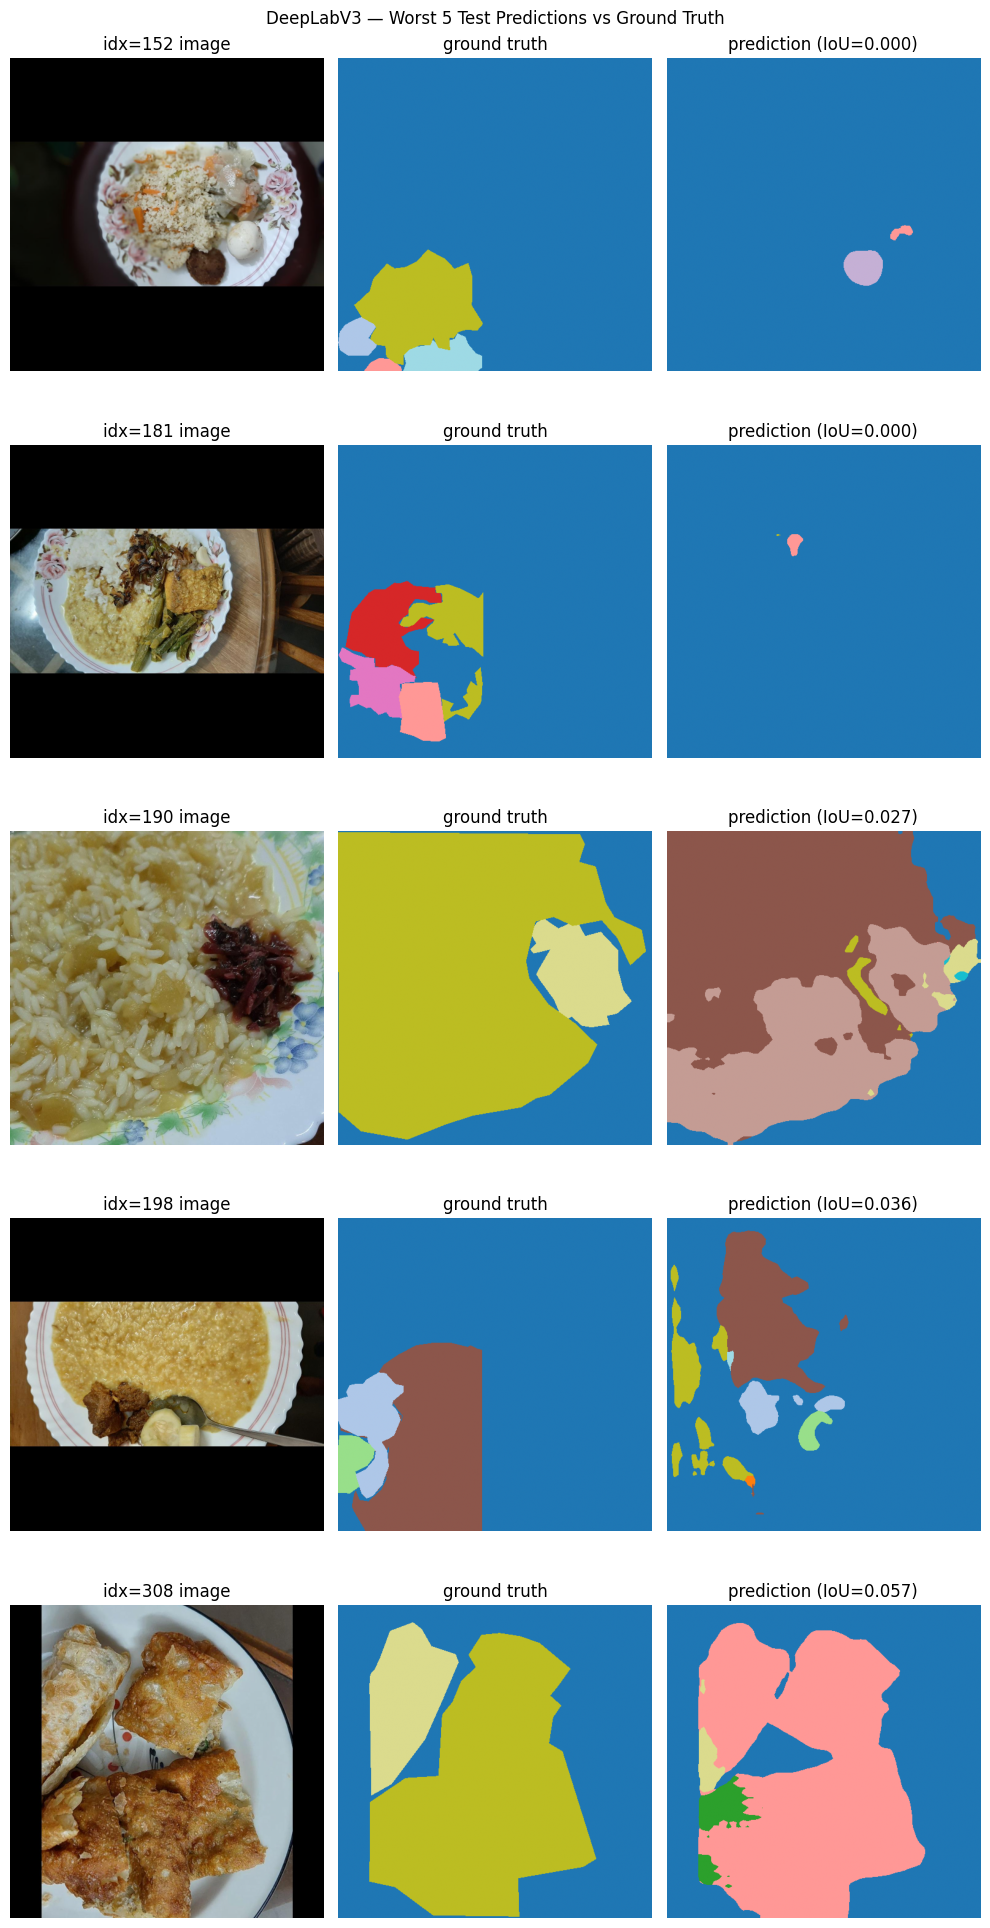

In [15]:
per_image_ious_sorted = sorted(per_image_ious, key=lambda x: (np.nan if np.isnan(x[1]) else x[1]))
worst_5 = [x for x in per_image_ious_sorted if not np.isnan(x[1])][:5]
print("Worst 5 test images (by mean per-image IoU, excluding background):")
for idx, iou in worst_5:
    print(f"  idx={idx}, IoU={iou:.4f}")

def get_test_image_mask(idx):
    img_t, mask_t = test_ds[idx]
    return img_t, mask_t

def denorm(img_t):
    mean = np.array([0.485,0.456,0.406]).reshape(3,1,1)
    std  = np.array([0.229,0.224,0.225]).reshape(3,1,1)
    img = img_t.numpy()*std + mean
    return np.clip(img.transpose(1,2,0), 0, 1)

fig, axes = plt.subplots(len(worst_5), 3, figsize=(10, 4*len(worst_5)))
model.eval()
with torch.no_grad():
    for row, (idx, iou) in enumerate(worst_5):
        img_t, mask_t = get_test_image_mask(idx)
        pred = model(img_t.unsqueeze(0).to(device))["out"].argmax(1).squeeze(0).cpu().numpy()

        img_np = denorm(img_t)
        axes[row,0].imshow(img_np); axes[row,0].set_title(f"idx={idx} image"); axes[row,0].axis("off")
        axes[row,1].imshow(mask_t.numpy(), cmap="tab20", vmin=0, vmax=NUM_CLASSES); axes[row,1].set_title("ground truth"); axes[row,1].axis("off")
        axes[row,2].imshow(pred, cmap="tab20", vmin=0, vmax=NUM_CLASSES); axes[row,2].set_title(f"prediction (IoU={iou:.3f})"); axes[row,2].axis("off")

plt.suptitle("DeepLabV3 — Worst 5 Test Predictions vs Ground Truth")
plt.tight_layout()
plt.savefig("deeplabv3_worst_predictions.png", dpi=150)
plt.show()

# Save worst indices for cross-model comparison in NB3's Task H (do same images fail across models?)
worst_indices = [idx for idx, _ in worst_5]
with open("deeplabv3_worst_indices.json", "w") as f:
    json.dump(worst_indices, f)

Most confused class pairs

In [16]:
conf_no_bg = conf_mat_test.copy()
np.fill_diagonal(conf_no_bg, 0)
conf_no_bg[0,:] = 0; conf_no_bg[:,0] = 0  # exclude background from "confusion" analysis

flat_indices = np.dstack(np.unravel_index(np.argsort(-conf_no_bg.ravel()), conf_no_bg.shape))[0]
print("Top 10 most confused class pairs (true -> predicted):")
seen_pairs = set()
count = 0
for t, p in flat_indices:
    if t == p or conf_no_bg[t,p] == 0:
        continue
    pair_key = tuple(sorted((t,p)))
    if pair_key in seen_pairs:
        continue
    seen_pairs.add(pair_key)
    print(f"  {CLASS_NAMES[t]} <-> {CLASS_NAMES[p]}: {conf_no_bg[t,p] + conf_no_bg[p,t]} pixels")
    count += 1
    if count >= 10:
        break

Top 10 most confused class pairs (true -> predicted):
  rice <-> khichuri: 165926 pixels
  vaji <-> vegetable: 141555 pixels
  puri <-> egg-poached: 94465 pixels
  rice <-> ruti: 82795 pixels
  ruti <-> egg-poached: 69913 pixels
  rice <-> lau: 63339 pixels
  shak <-> lal-shak: 69582 pixels
  guava <-> salad: 54921 pixels
  kumra-vaji <-> lau: 88107 pixels
  daal <-> vegetable: 70724 pixels


Save NB1 outputs for NB3's Task H comparison

In [17]:
import shutil
os.makedirs("/kaggle/working/nb1_outputs", exist_ok=True)
for f in ["deeplabv3_test_summary.json", "deeplabv3_test_metrics_per_class.csv",
          "deeplabv3_worst_indices.json", "deeplabv3_best.pth",
          "deeplabv3_training_curves.png", "deeplabv3_confusion_matrix.png",
          "deeplabv3_worst_predictions.png"]:
    shutil.copy(f, f"/kaggle/working/nb1_outputs/{f}")

print("NB1 outputs saved — publish this notebook's output as a dataset (e.g. 'food-seg-nb1-deeplabv3-outputs') so NB3 can pull these metrics for the final comparison.")

NB1 outputs saved — publish this notebook's output as a dataset (e.g. 'food-seg-nb1-deeplabv3-outputs') so NB3 can pull these metrics for the final comparison.
